In [ ]:

from google.colab import files

uploaded = files.upload()

Saving zomato.csv to zomato.csv


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("zomato.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (7105, 12)

First 5 Rows:


,Unnamed: 0.1,Unnamed: 0,restaurant name,restaurant type,rate (out of 5),num of ratings,avg cost (two people),online_order,table booking,cuisines type,area,local address
0,0,0,#FeelTheROLL,Quick Bites,3.4,7,200.0,No,No,Fast Food,Bellandur,Bellandur
1,1,1,#L-81 Cafe,Quick Bites,3.9,48,400.0,Yes,No,"Fast Food, Beverages","Byresandra,Tavarekere,Madiwala",HSR
2,2,2,#refuel,Cafe,3.7,37,400.0,Yes,No,"Cafe, Beverages",Bannerghatta Road,Bannerghatta Road
3,3,3,'@ Biryani Central,Casual Dining,2.7,135,550.0,Yes,No,"Biryani, Mughlai, Chinese",Marathahalli,Marathahalli
4,4,4,'@ The Bbq,Casual Dining,2.8,40,700.0,Yes,No,"BBQ, Continental, North Indian, Chinese, Bever...",Bellandur,Bellandur



Column Names:
['Unnamed: 0.1', 'Unnamed: 0', 'restaurant name', 'restaurant type', 'rate (out of 5)', 'num of ratings', 'avg cost (two people)', 'online_order', 'table booking', 'cuisines type', 'area', 'local address']


In [ ]:

features = [
    "rate (out of 5)",
    "num of ratings",
    "avg cost (two people)"
]

X = df[features].copy()

for col in features:
    X[col] = pd.to_numeric(X[col], errors="coerce")

print("Missing values before treatment:")
print(X.isnull().sum())

X = X.fillna(X.mean())

print("\nMissing values after treatment:")
print(X.isnull().sum())

display(X.head())

Missing values before treatment:
rate (out of 5)          68
num of ratings            0
avg cost (two people)    57
dtype: int64

Missing values after treatment:
rate (out of 5)          0
num of ratings           0
avg cost (two people)    0
dtype: int64


,rate (out of 5),num of ratings,avg cost (two people)
0,3.4,7,200.0
1,3.9,48,400.0
2,3.7,37,400.0
3,2.7,135,550.0
4,2.8,40,700.0


In [ ]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=features
)

print("Standardized Data:")
display(X_scaled.head())

print("\nStandardized Shape:", X_scaled.shape)

Standardized Data:


,rate (out of 5),num of ratings,avg cost (two people)
0,-0.247841,-0.307232,-0.738134
1,0.836772,-0.237990,-0.304303
2,0.402927,-0.256567,-0.304303
3,-1.766300,-0.091063,0.021070
4,-1.549377,-0.251501,0.346443



Standardized Shape: (7105, 3)


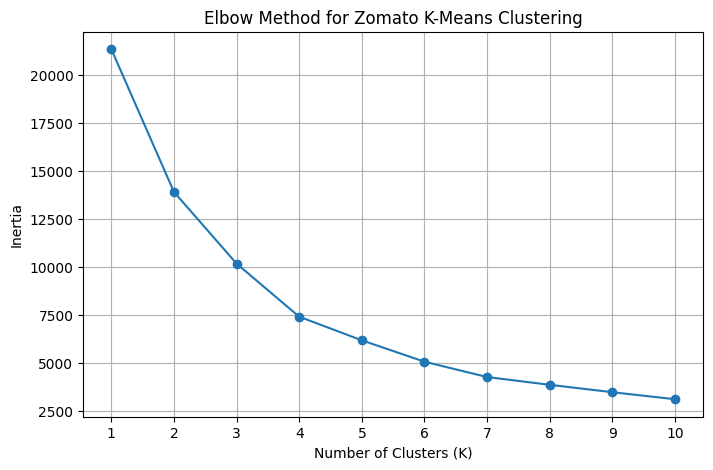

In [ ]:

from sklearn.cluster import KMeans

inertias = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=10,
        n_init=10
    )
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.title("Elbow Method for Zomato K-Means Clustering")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [ ]:

kmeans = KMeans(
    n_clusters=3,
    random_state=10,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

df_results = X.copy()
df_results["Cluster"] = clusters

print("Cluster Sizes:")
print(df_results["Cluster"].value_counts().sort_index())

print("\nCluster Centroids (Standardized):")
centroids = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=features
)
display(centroids)

print("\nInertia:", kmeans.inertia_)

Cluster Sizes:
Cluster
0    2978
1    3528
2     599
Name: count, dtype: int64

Cluster Centroids (Standardized):


,rate (out of 5),num of ratings,avg cost (two people)
0,-0.963118,-0.249644,-0.323818
1,0.566707,-0.091994,-0.138383
2,1.442423,1.776199,2.415803



Inertia: 10172.451395165657


In [ ]:

from sklearn.metrics import silhouette_score, davies_bouldin_score

silhouette = silhouette_score(X_scaled, clusters)
db_index = davies_bouldin_score(X_scaled, clusters)

print(f"Silhouette Score: {silhouette:.4f}")
print(f"Davies-Bouldin Index: {db_index:.4f}")
print(f"Inertia: {kmeans.inertia_:.4f}")

Silhouette Score: 0.4001
Davies-Bouldin Index: 0.9239
Inertia: 10172.4514


In [ ]:

from sklearn.metrics import silhouette_score, davies_bouldin_score

silhouette = silhouette_score(X_scaled, clusters)
db_index = davies_bouldin_score(X_scaled, clusters)

print(f"Silhouette Score: {silhouette:.4f}")
print(f"Davies-Bouldin Index: {db_index:.4f}")
print(f"Inertia: {kmeans.inertia_:.4f}")

Silhouette Score: 0.4001
Davies-Bouldin Index: 0.9239
Inertia: 10172.4514


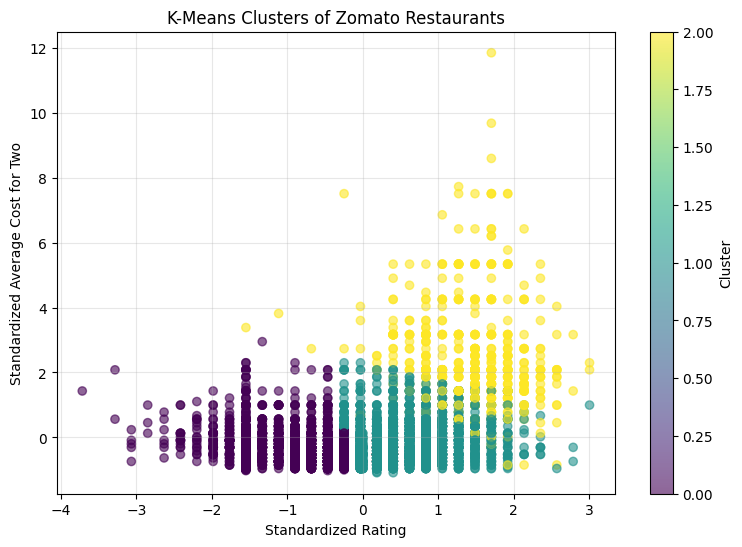

In [ ]:

plt.figure(figsize=(9, 6))

plt.scatter(
    X_scaled["rate (out of 5)"],
    X_scaled["avg cost (two people)"],
    c=clusters,
    cmap="viridis",
    alpha=0.6
)

plt.title("K-Means Clusters of Zomato Restaurants")
plt.xlabel("Standardized Rating")
plt.ylabel("Standardized Average Cost for Two")
plt.colorbar(label="Cluster")
plt.grid(True, alpha=0.3)
plt.show()

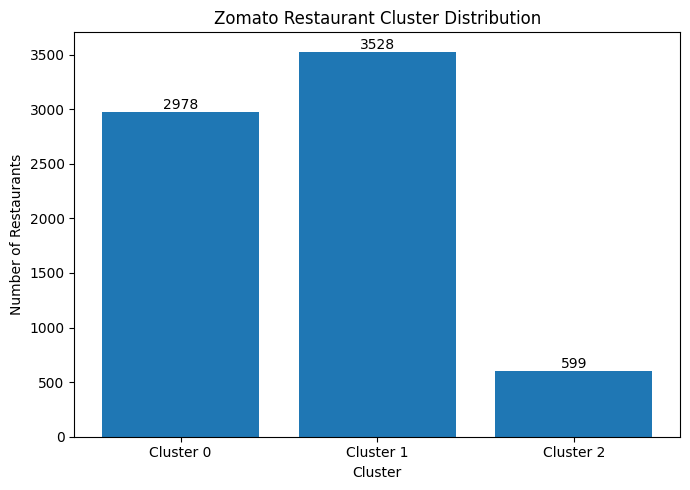

In [ ]:

cluster_counts = (
    pd.Series(clusters)
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(7, 5))
plt.bar(
    [f"Cluster {i}" for i in cluster_counts.index],
    cluster_counts.values
)

plt.title("Zomato Restaurant Cluster Distribution")
plt.xlabel("Cluster")
plt.ylabel("Number of Restaurants")

for i, count in enumerate(cluster_counts.values):
    plt.text(i, count, str(count), ha="center", va="bottom")

plt.tight_layout()
plt.show()